# Linear Regression with scikit-learn

## What's in this notebook

- Scaling features with `StandardScaler`
- `SGDRegressor`: gradient descent in scikit-learn
- Predicting and comparing with the targets
- Normal equation vs gradient descent
- Batch vs mini-batch vs stochastic gradient descent
- Checking the assumptions of linear regression

## Goals
In this lab you will:
- Utilize  scikit-learn to implement linear regression using Gradient Descent

## Tools
You will utilize functions from scikit-learn as well as matplotlib and NumPy. 

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler


# Gradient Descent
Scikit-learn has a gradient descent regression model [sklearn.linear_model.SGDRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html#examples-using-sklearn-linear-model-sgdregressor).  Like your previous implementation of gradient descent, this model performs best with normalized inputs. [sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler) will perform z-score normalization as in a previous lab. Here it is referred to as 'standard score'.

In [8]:
def load_house_data():
    data = np.loadtxt("./data/houses.txt", delimiter=',', skiprows=1)
    X = data[:,:4]
    y = data[:,4]
    return X, y

# Load
x_train, y_train = load_house_data()
X_features = ['size(sqft)','bedrooms','floors','age']

# Scale / Normalize 
scaler = StandardScaler()
x_norm = scaler.fit_transform(x_train)
print(f"Peak to Peak range by column in Raw        X:{np.ptp(x_train,axis=0)}")   
print(f"Peak to Peak range by column in Normalized X:{np.ptp(x_norm,axis=0)}")

# Train
sgdr = SGDRegressor(max_iter = 1000)
sgdr.fit(x_norm, y_train)
print(sgdr)
print(f"number of iterations completed: {sgdr.n_iter_}, number of weight updates: {sgdr.t_}")

w_norm = sgdr.coef_
b_norm = sgdr.intercept_
print(f"model parameters:                   w: {w_norm}, b:{b_norm}")
print( "model parameters from previous lab: w: [110.56 -21.27 -32.71 -37.97], b: 363.16")

# Query / Predict using training data 
y_pred_sgd = sgdr.predict(x_norm) # make a prediction using sgdr.predict()
y_pred = np.dot(x_norm, w_norm) + b_norm  # make a prediction using w,b. 
print(f"prediction using np.dot() and sgdr.predict match: {(y_pred == y_pred_sgd).all()}")

print(f"Prediction on training set using sckit model:\n{y_pred_sgd[:4]}" )
print(f"Prediction on training set using maths:\n{y_pred[:4]}" )
print(f"Target values \n{y_train[:4]}")


Peak to Peak range by column in Raw        X:[2.406e+03 4.000e+00 1.000e+00 9.500e+01]
Peak to Peak range by column in Normalized X:[5.8452591  6.13529646 2.05626214 3.68533012]
SGDRegressor()
number of iterations completed: 131, number of weight updates: 12970.0
model parameters:                   w: [110.17152321 -21.15779382 -32.59001354 -38.0210609 ], b:[363.12707745]
model parameters from previous lab: w: [110.56 -21.27 -32.71 -37.97], b: 363.16
prediction using np.dot() and sgdr.predict match: True
Prediction on training set using sckit model:
[295.21626972 485.68765543 389.39422658 491.84942935]
Prediction on training set using maths:
[295.21626972 485.68765543 389.39422658 491.84942935]
Target values 
[300.  509.8 394.  540. ]


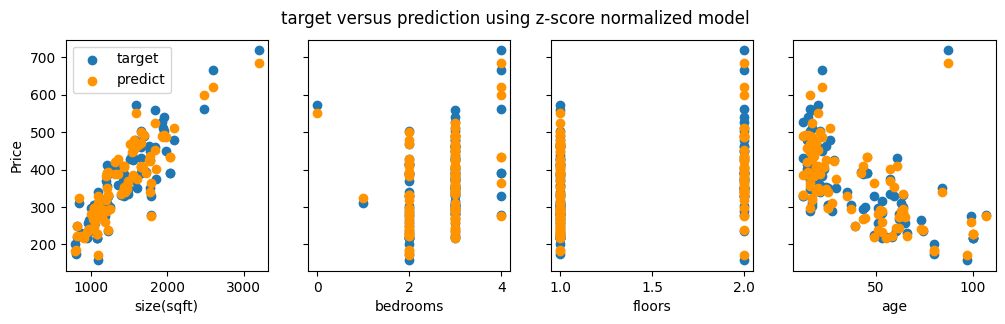

In [9]:
# plot predictions and targets vs original features    
dlc = dict(dlblue = '#0096ff', dlorange = '#FF9300', dldarkred='#C00000', dlmagenta='#FF40FF', dlpurple='#7030A0')

fig,ax=plt.subplots(1,4,figsize=(12,3),sharey=True)
for i in range(len(ax)):
    ax[i].scatter(x_train[:,i],y_train, label = 'target')
    ax[i].set_xlabel(X_features[i])
    ax[i].scatter(x_train[:,i],y_pred,color=dlc["dlorange"], label = 'predict')
ax[0].set_ylabel("Price"); ax[0].legend();
fig.suptitle("target versus prediction using z-score normalized model")
plt.show()

# Normal Equation vs Gradient Descent

Linear regression has a closed-form solution, the **normal equation** (with a column of 1s in X for the bias):

```text
w = (XᵀX)⁻¹ Xᵀ y
```

One step, no learning rate, no feature scaling. sklearn's `LinearRegression` solves the same least-squares problem with a stable solver
(it doesn't invert XᵀX directly). `SGDRegressor`, used above, gets there with gradient descent instead.

In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

import numpy as np
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, SGDRegressor

X_reg, y_reg = make_regression(n_samples=1000, n_features=5, noise=10, random_state=0)
X_bias = np.c_[np.ones(len(X_reg)), X_reg]                       # column of 1s for the bias
w = np.linalg.solve(X_bias.T @ X_bias, X_bias.T @ y_reg)          # solve, don't invert

ols = LinearRegression().fit(X_reg, y_reg)
sgd = SGDRegressor(max_iter=1000, tol=1e-6, random_state=0).fit(X_reg, y_reg)
print("normal equation weights:", w[1:].round(2))
print(f"largest difference from LinearRegression: {np.abs(w[1:] - ols.coef_).max():.1e}")
print(f"largest difference of SGDRegressor from LinearRegression: {np.abs(sgd.coef_ - ols.coef_).max():.3f}")


normal equation weights: [40.75 66.67 11.09 60.41 25.43]
largest difference from LinearRegression: 1.1e-13
largest difference of SGDRegressor from LinearRegression: 0.048


The normal equation matches `LinearRegression` to floating-point precision (1.1e-13). Gradient descent lands within 0.048 of the same weights
(which are between 11 and 67 here): close, but it stops when the improvement gets tiny, not at the exact answer.

| | Normal equation | Gradient descent |
|---|---|---|
| Steps | one exact solve | many iterations |
| Hyperparameters | none | learning rate, iterations; needs scaled features |
| Cost | about O(n·d² + d³): fine for thousands of features, slow for very many | O(n·d) per epoch: scales to huge n and d, and to data that doesn't fit in memory |
| Works for | linear regression (and ridge) only | any differentiable model, including neural networks |
| Fails when | XᵀX is singular (duplicate or perfectly collinear features): use the pseudo-inverse or ridge | doesn't fail, but can converge slowly |

# Batch vs Mini-batch vs Stochastic Gradient Descent

| Variant | Rows per update | Gain | Cost |
|---|---|---|---|
| Batch | all n rows | smooth, steady progress; exact gradient | one update per pass over the data; slow and memory-hungry on big data |
| Stochastic (SGD) | 1 row | many cheap updates; can learn from streaming data | very noisy; needs a decaying learning rate to settle |
| Mini-batch | 32 to a few thousand | the best of both; fits GPU hardware well; the noise can help escape poor regions | one more hyperparameter (batch size) |

Mini-batch is the standard in deep learning, and in deep-learning code "SGD" usually means mini-batch. `SGDRegressor` above updates on one row at a time.

# Checking the Assumptions of Linear Regression

| Assumption | If it fails | How to check | Fix |
|---|---|---|---|
| **L**inearity | predictions are biased in a pattern | residuals vs fitted values: a curve means a missing pattern | add features (polynomial, log), or use a non-linear model |
| **I**ndependent errors | standard errors and p-values are wrong | residuals over time (autocorrelation, Durbin-Watson) | time-series models, lag features |
| **N**ormal errors | p-values and intervals on small samples | Q-Q plot of the residuals | usually fine with large n |
| **E**qual variance (homoscedasticity) | intervals and p-values are wrong (predictions stay unbiased) | residual spread grows with the fitted value (a funnel) | log the target, weighted least squares, robust standard errors |
| No strong multicollinearity | unstable, hard-to-read coefficients | VIF (`13-ml-fundamentals/3-ml-feature-engineering.ipynb`) | drop or combine features, ridge |

For pure prediction mostly linearity matters. The others matter when you read coefficients, p-values or intervals.
Below, three datasets: one that meets the assumptions, one with a curve, one whose noise grows with x.

assumptions hold     R² 0.936   mean residual by third [0.03, -0.08, 0.05]   residual std by third [0.45, 0.42, 0.48]
curved (y = x²)      R² 0.915   mean residual by third [0.47, -0.81, 0.31]   residual std by third [0.74, 0.43, 0.65]
noise grows with x   R² 0.625   mean residual by third [0.02, -0.18, 0.13]   residual std by third [0.57, 1.03, 1.72]


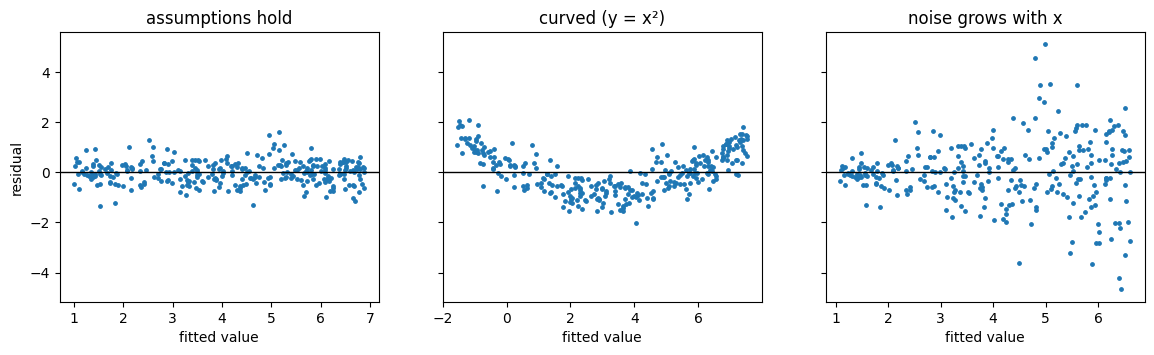

In [2]:

import matplotlib.pyplot as plt

x = np.random.default_rng(0).uniform(0, 3, 300)
noise = np.random.default_rng(1).normal(0, 1, 300)
cases = {
    "assumptions hold": 2 * x + 1 + 0.5 * noise,
    "curved (y = x²)": x ** 2 + 0.5 * noise,
    "noise grows with x": 2 * x + 1 + (0.3 + 0.6 * x) * noise,
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, y_case) in zip(axes, cases.items()):
    model = LinearRegression().fit(x.reshape(-1, 1), y_case)
    fitted = model.predict(x.reshape(-1, 1))
    residuals = y_case - fitted
    thirds = np.digitize(x, [1, 2])                                 # x in [0, 1), [1, 2), [2, 3]
    print(f"{name:<20} R² {model.score(x.reshape(-1, 1), y_case):.3f}   "
          f"mean residual by third {[round(float(residuals[thirds == k].mean()), 2) for k in range(3)]}   "
          f"residual std by third {[round(float(residuals[thirds == k].std()), 2) for k in range(3)]}")
    ax.scatter(fitted, residuals, s=6)
    ax.axhline(0, color="black", lw=1)
    ax.set(title=name, xlabel="fitted value")
axes[0].set_ylabel("residual")
plt.show()


- **Assumptions hold:** residuals average about 0 in every third of the data with the same spread (std 0.42–0.48): a shapeless band around 0.
- **Curved:** the residuals average +0.47, −0.81, +0.31 across the thirds, a U shape that a straight line can't follow. R² is still 0.915:
  a high R² doesn't mean the model is right.
- **Noise grows with x:** the residual std rises from 0.57 to 1.03 to 1.72, a funnel. The line is still unbiased, but its confidence intervals are wrong.